# Day 9 · ANN 학습부터 저장·복원까지

기존 `day9_ann`의 구현을 셀 단위로 나눈 실행용 노트북입니다. 위에서부터 **모두 실행**하세요.
프로젝트 `.venv`의 PyTorch·matplotlib이 설치된 Python 커널을 선택합니다.

입력은 `x1`, `x2`, 정답은 클래스 `label`입니다. train 120건·valid 40건으로 학습·검증하고 test 40건은 사용하지 않습니다.
모델은 2→8→2, CrossEntropyLoss, SGD(lr=0.1), batch 32, 80 epoch로 기존 코드와 같습니다.

생성물은 `outputs/notebook/`에 저장합니다. 이 노트북은 `data/points.csv`가 함께 있는 프로젝트 폴더를 기준으로 실행합니다.


## 1. 환경과 경로

노트북 폴더 또는 저장소 루트에서 실행할 수 있습니다. CUDA를 사용할 수 있으면 GPU, 아니면 CPU를 선택합니다.
다른 장치·버전에서 같은 seed를 써도 마지막 비트까지 같은 결과를 보장하지는 않습니다.


In [1]:
from pathlib import Path
import copy
import csv
import json
import platform
import subprocess
import sys
import unittest

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

relative = Path("20261029/03_심화/day9_ann")
locations = [Path.cwd(), Path.cwd() / relative]
locations += [parent / relative for parent in Path.cwd().parents]
base = next((p.resolve() for p in locations if (p / "model.py").is_file() and (p / "data/points.csv").is_file()), None)
if base is None:
    raise FileNotFoundError("day9_ann 폴더 또는 저장소 안에서 노트북을 실행하세요.")
out = base / "outputs/notebook"
out.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
environment = {
    "python": platform.python_version(), "torch": str(torch.__version__),
    "cuda_build": torch.version.cuda, "cuda_available": torch.cuda.is_available(),
    "selected_device": str(device),
}
print(json.dumps(environment, ensure_ascii=False, indent=2))
print("데이터 경로:", base / "data/points.csv")
print("결과 경로:", out)


/home/swchoi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-0hxnxmdq because there was an issue with the default path (/home/swchoi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
{
  "python": "3.13.16",
  "torch": "2.14.0+cu130",
  "cuda_build": "13.0",
  "cuda_available": false,
  "selected_device": "cpu"
}
데이터 경로: /home/swchoi/projects/python/practice_assignment/20261029/03_심화/day9_ann/data/points.csv
결과 경로: /home/swchoi/projects/python/practice_assignment/20261029/03_심화/day9_ann/outputs/notebook


## 2. 데이터와 Tensor shape

입력 X는 `(표본 수, 2)`의 실수 Tensor, 정답 y는 `(표본 수,)`의 `torch.long` Tensor입니다.
정답은 one-hot으로 바꾸지 않고 클래스 인덱스를 사용합니다. 제공된 split과 행 순서를 유지합니다.


In [2]:
with (base / "data/points.csv").open(encoding="utf-8", newline="") as f:
    rows = list(csv.DictReader(f))
train_rows = [r for r in rows if r["split"] == "train"]
valid_rows = [r for r in rows if r["split"] == "valid"]
X_train = torch.tensor([[float(r["x1"]), float(r["x2"])] for r in train_rows])
y_train = torch.tensor([int(r["label"]) for r in train_rows], dtype=torch.long)
X_valid = torch.tensor([[float(r["x1"]), float(r["x2"])] for r in valid_rows])
y_valid = torch.tensor([int(r["label"]) for r in valid_rows], dtype=torch.long)
assert len(train_rows) == 120 and len(valid_rows) == 40
print("X_train:", tuple(X_train.shape), X_train.dtype)
print("y_train:", tuple(y_train.shape), y_train.dtype)
print("X_valid:", tuple(X_valid.shape), "y_valid:", tuple(y_valid.shape))
print("test 40건은 Tensor 생성·학습·예측·평가에 사용하지 않습니다.")


X_train: (120, 2) torch.float32
y_train: (120,) torch.int64
X_valid: (40, 2) y_valid: (40,)
test 40건은 Tensor 생성·학습·예측·평가에 사용하지 않습니다.


## 3. 모델 구조

`nn.Linear(2, 8)` → `ReLU` → `nn.Linear(8, 2)`로 두 클래스의 logits를 출력합니다.
CrossEntropyLoss가 logits를 받으므로 마지막에 Softmax를 추가하지 않습니다.
아래 클래스는 `model.py`와 같은 구조입니다.


In [3]:
from torch import nn

class SimpleANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2,8), nn.ReLU(), nn.Linear(8,2))

    def forward(self, x):
        return self.net(x)


## 4. 한 epoch 학습과 평가

학습은 `zero_grad → forward/loss → backward → step` 순서입니다.
배치마다 가중치가 달라지는 **online loss**는 `배치 평균 loss × 표본 수`를 합한 뒤 전체 표본 수로 나눕니다.
120건을 32·32·32·24건으로 나누므로 마지막 배치를 같은 비중으로 단순 평균하면 안 됩니다.

평가는 `eval()`로 모드를 전환하고 `no_grad()`로 gradient 기록을 끕니다.
`argmax(dim=1)`은 각 표본에서 가장 큰 logit의 클래스 인덱스를 선택합니다.


In [4]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    total, count = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        count += len(yb)
    return total / count

def evaluate(model, X, y, loss_fn, device):
    model.eval()
    with torch.no_grad():
        logits = model(X.to(device))
        loss = loss_fn(logits, y.to(device)).item()
        prediction = torch.argmax(logits, dim=1).cpu()
    return loss, (prediction == y.cpu()).float().mean().item(), prediction


## 5. 학습 준비

이 셀을 다시 실행하면 모델·optimizer·DataLoader가 초기화됩니다. 이어서 학습 셀을 실행하면 처음부터 재현할 수 있습니다.
학습 셀만 다시 실행하면 현재 가중치에서 추가 학습하므로 처음과 다른 결과가 나옵니다.


In [5]:
torch.manual_seed(42)
model = SimpleANN().to(device)
loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=32, shuffle=True,
    generator=torch.Generator().manual_seed(43), num_workers=0,
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
initial_train_loss, _, _ = evaluate(model, X_train, y_train, loss_fn, device)
print(model)
print("파라미터 수:", sum(p.numel() for p in model.parameters()))
print("학습 전 고정 모델 train loss:", round(initial_train_loss, 6))


SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=2, bias=True)
  )
)
파라미터 수: 42
학습 전 고정 모델 train loss: 0.565832


## 6. 80 epoch 학습과 기록

원래 프로젝트에 더해, 각 epoch 종료 시 **동일한 고정 모델의 전체 train 평가 loss**도 기록합니다.
이는 online loss와 측정 시점이 다르므로 값이 일치할 필요가 없습니다.
`epoch % 10`은 출력 주기이며, 학습·평가·기록은 매 epoch 수행합니다.


In [6]:
history = []
for epoch in range(1, 81):
    online_loss = train_one_epoch(model, loader, loss_fn, optimizer, device)
    train_loss_eval, _, _ = evaluate(model, X_train, y_train, loss_fn, device)
    valid_loss, accuracy, prediction = evaluate(model, X_valid, y_valid, loss_fn, device)
    history.append({
        "epoch": epoch, "train_loss_online": online_loss,
        "train_loss_eval": train_loss_eval, "valid_loss": valid_loss,
        "valid_accuracy": accuracy,
    })
    if epoch % 10 == 0:
        print(f"epoch={epoch:2d} | online={online_loss:.6f} | train_eval={train_loss_eval:.6f}"
              f" | valid_loss={valid_loss:.6f} | valid_accuracy={accuracy:.4f}")
assert len(history) == 80


epoch=10 | online=0.342276 | train_eval=0.331469 | valid_loss=0.281476 | valid_accuracy=0.9750
epoch=20 | online=0.234005 | train_eval=0.228078 | valid_loss=0.182579 | valid_accuracy=0.9750
epoch=30 | online=0.180513 | train_eval=0.176405 | valid_loss=0.134341 | valid_accuracy=1.0000
epoch=40 | online=0.147421 | train_eval=0.145632 | valid_loss=0.105641 | valid_accuracy=1.0000
epoch=50 | online=0.126812 | train_eval=0.125040 | valid_loss=0.086818 | valid_accuracy=1.0000
epoch=60 | online=0.111919 | train_eval=0.110228 | valid_loss=0.074174 | valid_accuracy=1.0000
epoch=70 | online=0.099610 | train_eval=0.098804 | valid_loss=0.064484 | valid_accuracy=1.0000
epoch=80 | online=0.090861 | train_eval=0.089844 | valid_loss=0.057217 | valid_accuracy=1.0000


## 7. loss와 정확도 그래프

세 loss를 비교하고 valid 정확도의 변화를 확인합니다. online loss가 항상 평가 loss보다 크다는 보장은 없습니다.
현재 valid의 높은 정확도를 새로운 데이터의 성능 보장으로 해석하지 않습니다.


day9_ann.ipynb:cell7:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


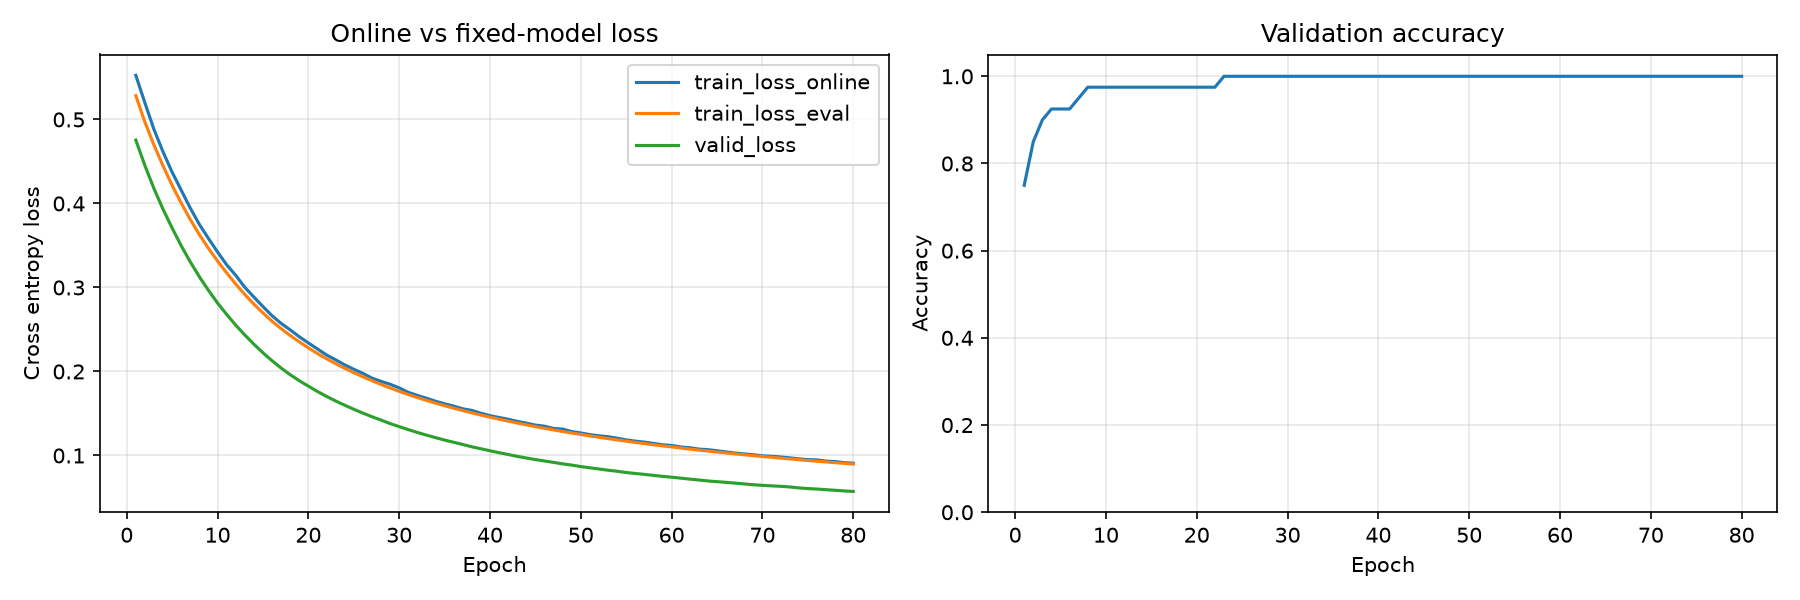

In [7]:
epochs = [r["epoch"] for r in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key in ["train_loss_online", "train_loss_eval", "valid_loss"]:
    axes[0].plot(epochs, [r[key] for r in history], label=key)
axes[0].set(xlabel="Epoch", ylabel="Cross entropy loss", title="Online vs fixed-model loss")
axes[0].legend()
axes[1].plot(epochs, [r["valid_accuracy"] for r in history])
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy", ylim=(0, 1.05))
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(out / "learning_curves.png", dpi=150)
plt.show()


## 8. state_dict와 실행 결과 저장

모델 전체 객체 대신 가중치·편향과 등록된 버퍼를 담은 `state_dict`를 저장합니다.
구조는 코드로 재생성합니다. 이 파일만으로 optimizer 상태와 난수 상태까지 복원해 학습을 정확히 이어갈 수는 없습니다.
노트북 결과는 기존 `outputs/` 파일을 덮어쓰지 않고 `outputs/notebook/`에 저장합니다.


In [8]:
model_state_path = out / "model_state.pt"
torch.save(model.state_dict(), model_state_path)
with (out / "training_history.csv").open("w", encoding="utf-8-sig", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)
with (out / "validation_predictions.csv").open("w", encoding="utf-8-sig", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["id", "actual", "predicted"])
    writer.writerows((r["id"], int(y), int(p)) for r, y, p in zip(valid_rows, y_valid, prediction))
metrics = {
    "epochs": 80, "device": str(device), "train_rows": len(train_rows),
    "valid_rows": len(valid_rows), "test_used": False,
    "initial_train_loss": initial_train_loss, **history[-1],
}
(out / "final_metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
(out / "environment.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metrics, ensure_ascii=False, indent=2))
print("저장 위치:", out)


{
  "epochs": 80,
  "device": "cpu",
  "train_rows": 120,
  "valid_rows": 40,
  "test_used": false,
  "initial_train_loss": 0.5658319592475891,
  "epoch": 80,
  "train_loss_online": 0.09086129665374756,
  "train_loss_eval": 0.08984403312206268,
  "valid_loss": 0.05721661448478699,
  "valid_accuracy": 1.0
}
저장 위치: /home/swchoi/projects/python/practice_assignment/20261029/03_심화/day9_ann/outputs/notebook


## 9. 새 CPU 모델로 복원

저장한 파일을 `weights_only=True`, `map_location="cpu"`로 읽고 동일한 구조에 적용합니다.
추가 학습 없이 CSV의 ID 순서·예측을 대조합니다. 같은 커널의 새 모델 검사와 다음 셀의 새 프로세스 검사를 구분합니다.


In [9]:
restored_model = SimpleANN()
state = torch.load(model_state_path, map_location="cpu", weights_only=True)
restored_model.load_state_dict(state)
_, restored_accuracy, restored_prediction = evaluate(
    restored_model, X_valid, y_valid, loss_fn, torch.device("cpu")
)
with (out / "validation_predictions.csv").open(encoding="utf-8-sig", newline="") as f:
    saved = list(csv.DictReader(f))
same_ids = [r["id"] for r in valid_rows] == [r["id"] for r in saved]
same_prediction = restored_prediction.tolist() == [int(r["predicted"]) for r in saved]
print("ID 순서 동일:", same_ids)
print("예측 동일:", same_prediction)
print("복원 모델 valid 정확도:", restored_accuracy)
assert same_ids and same_prediction


ID 순서 동일: True
예측 동일: True
복원 모델 valid 정확도: 1.0


## 10. 별도 프로세스 복원

새 Python 프로세스에서 프로젝트의 `model.py`를 가져와 노트북이 만든 파일을 복원합니다.
노트북 메모리에 학습 모델이 남아 있어서 결과가 맞는 것인지 구분하기 위한 검사입니다.


In [10]:
restore_script = r"""
import csv
import sys
from pathlib import Path
import torch
from model import SimpleANN

base = Path(sys.argv[1])
out = base / "outputs/notebook"
with (base / "data/points.csv").open(encoding="utf-8", newline="") as f:
    valid = [r for r in csv.DictReader(f) if r["split"] == "valid"]
X = torch.tensor([[float(r["x1"]), float(r["x2"])] for r in valid])
model = SimpleANN()
model.load_state_dict(torch.load(out / "model_state.pt", map_location="cpu", weights_only=True))
model.eval()
with torch.no_grad():
    predicted = model(X).argmax(dim=1).tolist()
with (out / "validation_predictions.csv").open(encoding="utf-8-sig", newline="") as f:
    saved = list(csv.DictReader(f))
same_ids = [r["id"] for r in valid] == [r["id"] for r in saved]
same_prediction = predicted == [int(r["predicted"]) for r in saved]
print("새 프로세스 CPU / ID 순서:", same_ids, "/ 예측:", same_prediction)
assert same_ids and same_prediction
"""
result = subprocess.run(
    [sys.executable, "-c", restore_script, str(base)],
    cwd=base, capture_output=True, text=True, check=True,
)
print(result.stdout)


새 프로세스 CPU / ID 순서: True / 예측: True



## 11. H11·H12 자동검사

H11은 학습률 0에서 7개 표본을 3·3·1로 나눈 손실의 가중 평균을 전체 손실과 비교합니다.
H12는 평가 전후 파라미터와 기존 gradient의 일치, 예측 Tensor의 `requires_grad=False`를 검사합니다.
아래 테스트는 프로젝트 테스트와 같은 내용이며, 이 노트북에서 정의한 함수를 대상으로 실행합니다.


In [11]:
class TrainingChecks(unittest.TestCase):
    def setUp(self):
        torch.manual_seed(42)
        torch.set_num_threads(1)
        self.model = SimpleANN()
        self.X = torch.tensor([[1.,2.], [-1.,0.], [2.,1.], [0.,0.], [1.,-1.], [-2.,1.], [3.,2.]])
        self.y = torch.tensor([1,0,1,0,1,0,1])

    def test_last_batch_weighting(self):
        loader = DataLoader(TensorDataset(self.X, self.y), batch_size=3, shuffle=False)
        loss_fn = nn.CrossEntropyLoss()
        # lr=0은 검사용입니다. 가중치를 고정해야 배치 분할 효과만 비교할 수 있습니다.
        optimizer = torch.optim.SGD(self.model.parameters(), lr=0.0)
        expected = loss_fn(self.model(self.X), self.y).item()
        actual = train_one_epoch(self.model, loader, loss_fn, optimizer, torch.device("cpu"))
        # H11 요구: 7건을 3·3·1로 나눈 손실이 전체 손실과 소수점5자리까지 같음을 검사하세요.
        # 수치를 출력만 하지 말고 self.assertAlmostEqual을 사용합니다.
        # >>> H11
        # TODO H11: actual과 expected가 같은지 검사하세요.
        self.assertAlmostEqual(actual, expected, places=5)
        # <<< H11

    def test_evaluation_does_not_learn(self):
        self.model(self.X).sum().backward()
        before = copy.deepcopy(self.model.state_dict())
        grads = [p.grad.clone() for p in self.model.parameters()]
        # 원래 loss, accuracy도 같이 받아오지만 파라미터와 gradient가 변경되는지 확인할 때 사용하지 않는 값이므로 _로 받아 의도적으로 사용하지 않음을 명시
        _, _, prediction = evaluate(self.model, self.X, self.y, nn.CrossEntropyLoss(), torch.device("cpu"))
        # H12 요구: 평가 전후 각 Parameter 값과 기존 grad가 모두 같은지 assertTrue로 검사하세요.
        # 추가: prediction에 requires_grad가 없음을 assertFalse로 확인합니다.
        # 모델의 eval 모드 전환은 정상입니다. 이 단계는 모드 복구까지 요구하지 않습니다.
        # >>> H12
        # TODO H12: 가중치·gradient·예측의 그래프 여부를 검사하세요.
        # 평가 전후의 파라미터 값이 같은지 확인
        for name, parameter in self.model.named_parameters():
            self.assertTrue(torch.equal(before[name], parameter))
        # 평가 전후의 gradient가 같은지 확인
        for parameter, previous_grad in zip(self.model.parameters(), grads):
            self.assertTrue(torch.equal(previous_grad, parameter.grad))
        # 예측 Tensor가 gradient 추적을 요구하지 않는지 확인
        self.assertFalse(prediction.requires_grad)

suite = unittest.defaultTestLoader.loadTestsFromTestCase(TrainingChecks)
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
assert result.wasSuccessful()


test_evaluation_does_not_learn (__notebook__.TrainingChecks.test_evaluation_does_not_learn) ... ok
test_last_batch_weighting (__notebook__.TrainingChecks.test_last_batch_weighting) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.009s

OK


## 12. 정리와 실행 결과 해석

- 학습과 평가를 함수로 분리하고, 출력 주기는 바깥 epoch 반복문에서 정했습니다.
- online loss는 서로 다른 시점의 모델을 거친 배치 loss의 표본 가중 평균입니다.
- 고정 모델 평가 loss는 갱신이 끝난 동일한 모델로 전체 데이터를 평가한 값입니다.
- 모델 구조와 학습한 상태를 분리해 저장하고 CPU에서 복원했습니다.
- 저장·복원 일치와 테스트 통과는 현재 구현의 확인이며, 실제 업무 데이터에서의 성능 보장은 아닙니다.

기존 모듈 설명과 실행 기록은 [reports/learning_note.md](reports/learning_note.md)에서 확인할 수 있습니다.
